# Simulated Annealing for the CVRPTW

## 1. Introduction

SA assigns customers to truck routes and chooses visit orders, respecting capacity, customer windows, depot return and fleet limit. On the Solomon benchmark the objective is total distance, with travel time equal to distance and arcs truncated to one decimal. Vehicle count is reported without an objective penalty.

This notebook runs SA only. All 56 supplied instances are used with separate roles:

| Role | Instances | Seeds | Runs |
| --- | --- | --- | --- |
| Temperature tuning | C101, C201, R101, R201, RC101, RC201 | 101 and 102 | 12 settings x 6 instances x 2 seeds = 144 |
| Test campaign | The other 50 Solomon instances | 1-10 | 50 instances x 10 seeds = 500 |

Every full run has a 20-second nominal budget. The parameter setting is selected using only tuning gaps. Test rows report distance, gap, feasibility, elapsed time and proposed moves; summaries use mean and sample standard deviation. No other algorithm is run or compared, and nothing is exported automatically.



## 2. Imports and configuration

Install the project with pip install -e ".[dev]". Numba is a main dependency. QUICK_CHECK=True runs the workflow with one-second budgets, one tuning seed and two test seeds. Quick numbers are not valid benchmark results; the saved full campaign must use QUICK_CHECK=False.

The full workflow contains 644 timed SA runs, approximately 31 minutes with seven workers plus setup and demonstrations. Synthetic compilation is excluded from budgets; route construction is included. Results are displayed in this notebook, without automatic CSV saving.


In [1]:
import sys
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import vrplib
from scipy import stats

ROOT = Path.cwd().resolve()
while not (ROOT / 'src' / 'cvrp').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
for folder in (ROOT / 'src', ROOT / 'experiments'):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
import solomon_study as study
from cvrp import Solution
from cvrp.sa import SAParams, SAResult, sa
from cvrp.sa_static import warmup
from cvrp.sa_protocol import (
    execute_jobs, tuning_jobs, benchmark_jobs, choose_parameters,
    validate_runs, summarize,
)
from cvrp.viz import plot_routes

pd.set_option('display.float_format', '{:.3f}'.format)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})
CLASSES = ['C1', 'C2', 'R1', 'R2', 'RC1', 'RC2']
warmup()  # Synthetic compilation before timed runs.
print('Python:', sys.version.split()[0], '| Platform:', platform.platform())

Python: 3.14.7 | Platform: Windows-11-10.0.26300-SP0


In [2]:
QUICK_CHECK = False
WORKERS = study.WORKERS
TIME_LIMIT = 1.0 if QUICK_CHECK else study.TIME_LIMIT
TUNING = tuple(study.TUNING)
TUNE_SEEDS = tuple(study.TUNE_SEEDS[:1] if QUICK_CHECK else study.TUNE_SEEDS)
TEST_SEEDS = tuple(study.TEST_SEEDS[:2] if QUICK_CHECK else study.TEST_SEEDS)
GRID = study.ALGORITHMS['sa'][1]
print(f'Budget: {TIME_LIMIT:.0f} s | Workers: {WORKERS}')
print('Tuning seeds:', TUNE_SEEDS, '| Test seeds:', TEST_SEEDS, '| Grid:', GRID)
if QUICK_CHECK:
    print('QUICK CHECK ONLY: these one-second results are not valid benchmark results.')

Budget: 20 s | Workers: 7
Tuning seeds: (101, 102) | Test seeds: (1, 2, 3, 4, 5, 6, 7, 8, 9, 10) | Grid: {'initial_temperature_factor': [0.0025, 0.005, 0.01], 'final_temperature': [0.005, 0.01, 0.02, 0.05]}


## 3. Dataset loading and reference checks

The repository loader reads the supplied local .txt instances and distance-oriented .sol references, truncates Euclidean arcs to one decimal and retains the shared fleet constraints. Reference routes must be feasible and reproduce their stored cost.

All 56 files are checked: six tuning instances and fifty separate test instances. Reference routes are used for gap calculation, never as starting solutions or move-selection information.


In [3]:
names = sorted(p.stem for p in study.DATA.glob('*.txt'))
assert len(names) == 56 and set(TUNING).issubset(names)
TEST_NAMES = tuple(n for n in names if n not in TUNING)
assert len(TEST_NAMES) == 50
rows = []
for name in names:
    inst = study.load(name)
    reference = Solution([list(r) for r in vrplib.read_solution(study.DATA / f'{name}.sol')['routes']])
    assert reference.is_feasible(inst), (name, reference.violations(inst))
    assert np.isclose(reference.cost(inst), inst.best_known, rtol=0, atol=1e-6)
    rows.append(dict(instance=name, family=name[:-2],
                     split='tuning' if name in TUNING else 'test',
                     best_known=inst.best_known, reference_routes=len(reference)))
instances = pd.DataFrame(rows)
print('All 56 references are feasible and reproduce their costs.')
display(instances.groupby(['family', 'split']).size().unstack(fill_value=0).reindex(CLASSES))

All 56 references are feasible and reproduce their costs.


split,test,tuning
family,,
C1,8,1
C2,7,1
R1,11,1
R2,10,1
RC1,7,1
RC2,7,1


## 4. SA implementation

The public solver follows the repository parameter/result conventions:

```python
result = sa(inst, SAParams(time_limit=20.0), seed=1)
result.best        # shared Solution
result.cost        # shared distance evaluation
result.runtime     # elapsed seconds
result.iterations  # proposed SA move attempts
result.history     # best-improvement batch snapshots
```

`sa.py` contains the parameter/result classes and public solver. `sa_vrptw.py` contains construction and the independent route evaluator; `sa_static.py` contains the compiled static moves. The solver reads `inst.dist` without changing its rounding or modifying the input instance.

```
construct a randomized feasible initial solution
current = best = initial
until the time or move-attempt budget is reached:
    propose relocate, swap, reversal, short-chain move or route-tail exchange
    reject candidates that break capacity or time windows
    accept improvements, or worsening moves with probability exp(-delta / T)
    update best and cool according to elapsed time
validate best with the shared Solution evaluator
```

Temperature follows `T(t)=T0*(Tf/T0)**(t/L)`, with `T0=max(1, factor*initial_distance)`. Defaults are heuristic; the tuning section selects `factor` and `Tf` using only the reserved six instances. SA records history at improving batches rather than storing millions of rows. One history snapshot is not one move.

### 4.1 Construction and search on C101

Construction: 2440.1; after 256 move attempts: 2440.1


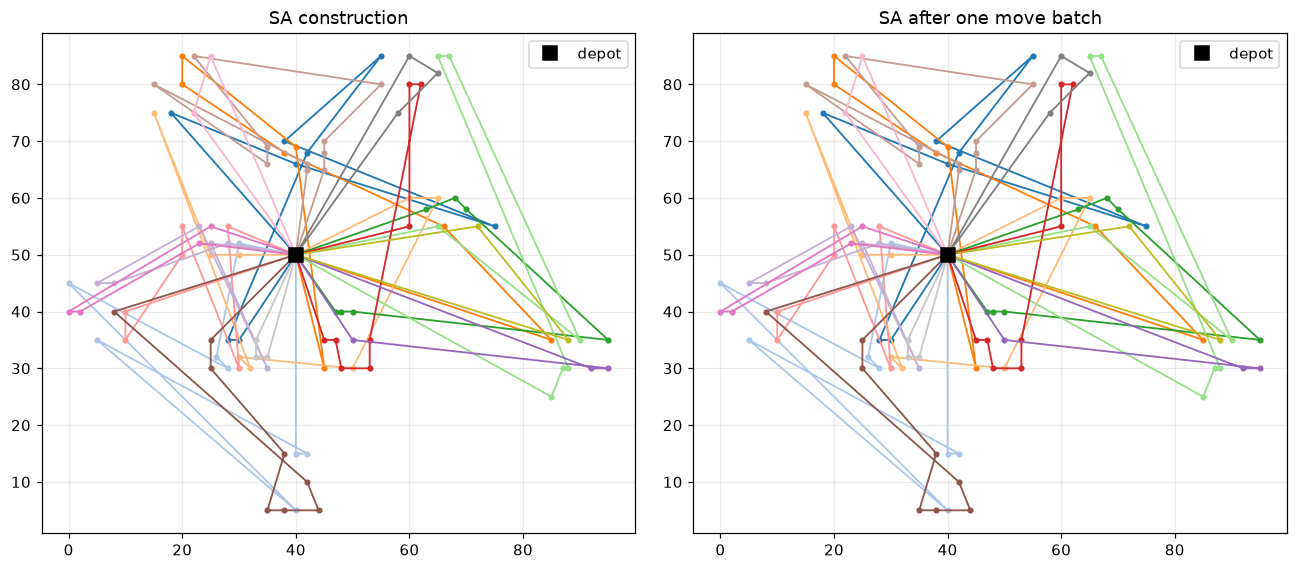

In [4]:
inst = study.load('C101')
demo = sa(inst, SAParams(iterations=256, time_limit=TIME_LIMIT), seed=1)
assert demo.best is not None and demo.best.is_feasible(inst)
print(f'Construction: {demo.initial.cost(inst):.1f}; after 256 move attempts: {demo.cost:.1f}')
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_routes(inst, demo.initial, ax=axes[0], title='SA construction')
plot_routes(inst, demo.best, ax=axes[1], title='SA after one move batch')
plt.tight_layout(); plt.show()

## 5. Single-instance testing

Use the same distance evaluator and nominal time budget as the campaign. The result includes the shared solution, number of proposed moves and convergence history. A seed controls the random sequence; wall-clock stopping can produce different move counts on different hardware.

RC101: distance 1640.9, reference 1619.8, gap 1.303%
85,806,848 proposed moves in 20.001 s; 17 routes; stop: time_limit


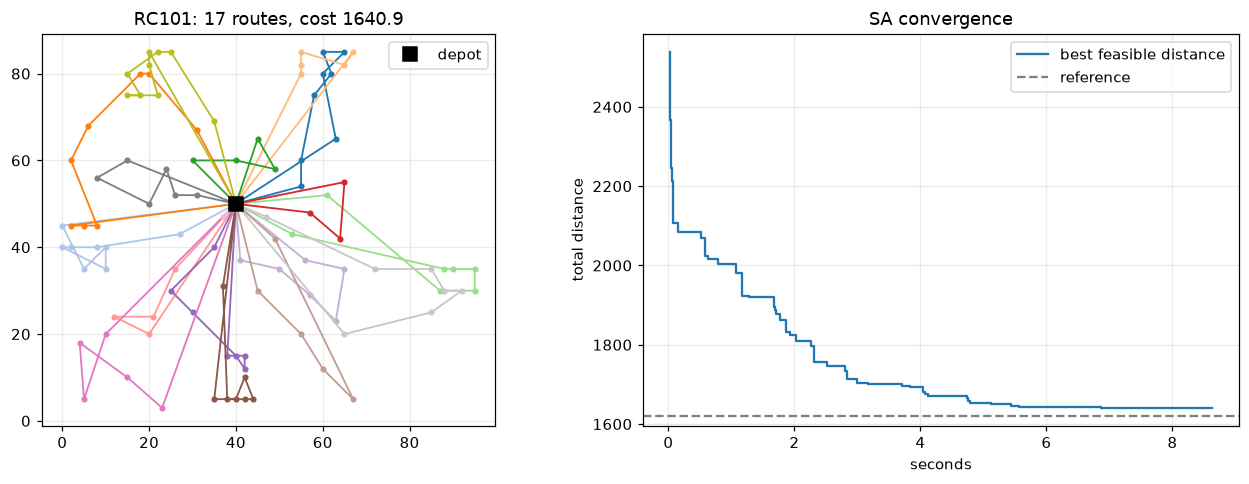

In [5]:
INSTANCE = 'RC101'
SEED = TEST_SEEDS[0]
inst = study.load(INSTANCE)
single = sa(inst, SAParams(time_limit=TIME_LIMIT), seed=SEED)
assert single.best is not None and single.best.violations(inst) == []
print(f'{INSTANCE}: distance {single.cost:.1f}, reference {inst.best_known:.1f}, '
      f'gap {100*(single.cost/inst.best_known-1):.3f}%')
print(f'{single.iterations:,} proposed moves in {single.runtime:.3f} s; '
      f'{len(single.best)} routes; stop: {single.stop_reason}')
h = pd.DataFrame(single.history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_routes(inst, single.best, ax=axes[0])
axes[1].step(h.seconds, h.best, where='post', label='best feasible distance')
axes[1].axhline(inst.best_known, ls='--', color='gray', label='reference')
axes[1].set(xlabel='seconds', ylabel='total distance', title='SA convergence')
axes[1].legend(); plt.tight_layout(); plt.show()

## 6. Parameter tuning on six instances

The grid uses initial-temperature factors 0.0025, 0.005 and 0.01, and final temperatures 0.005, 0.01, 0.02 and 0.05. Twelve settings are evaluated on six instances with seeds 101 and 102, at twenty seconds per run: 144 tuning runs.

The setting with the lowest mean tuning gap is selected. None of the fifty test instances participates in this selection. These grid values are candidates, not previously established optimal settings. Results stay in memory.


144 SA tuning runs


,params,mean_gap
0,"{'initial_temperature_factor': 0.01, 'final_te...",0.427
1,"{'initial_temperature_factor': 0.01, 'final_te...",0.507
2,"{'initial_temperature_factor': 0.005, 'final_t...",0.544
3,"{'initial_temperature_factor': 0.005, 'final_t...",0.546
4,"{'initial_temperature_factor': 0.0025, 'final_...",0.552
5,"{'initial_temperature_factor': 0.01, 'final_te...",0.558
6,"{'initial_temperature_factor': 0.01, 'final_te...",0.563
7,"{'initial_temperature_factor': 0.0025, 'final_...",0.566
8,"{'initial_temperature_factor': 0.005, 'final_t...",0.599
9,"{'initial_temperature_factor': 0.005, 'final_t...",0.599


Selected parameters: {'initial_temperature_factor': 0.01, 'final_temperature': 0.005}


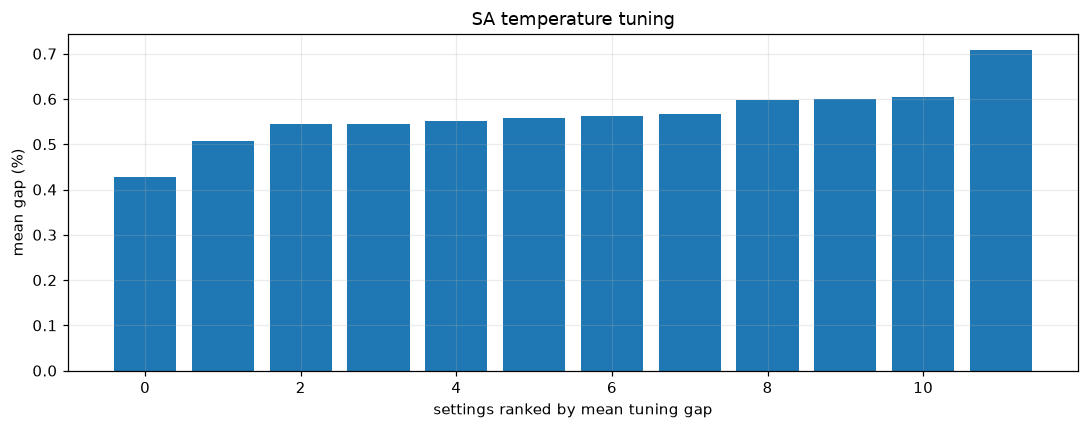

In [6]:
jobs = tuning_jobs(study, QUICK_CHECK)
print(f'{len(jobs)} SA tuning runs')
tuning = execute_jobs(jobs, study.run_one, WORKERS)
CHOSEN, tuning_ranking = choose_parameters(tuning)
assert set(tuning.instance) == set(TUNING)
assert set(tuning.seed) == set(TUNE_SEEDS)
display(tuning_ranking)
print('Selected parameters:', CHOSEN)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(len(tuning_ranking)), tuning_ranking.mean_gap)
ax.set(xlabel='settings ranked by mean tuning gap', ylabel='mean gap (%)', title='SA temperature tuning')
ax.ticklabel_format(axis='y', style='plain', useOffset=False)
plt.tight_layout(); plt.show()

## 7. Test campaign: fifty instances, ten seeds, twenty seconds

The selected temperature setting runs on the fifty instances not used for tuning, with seeds 1-10. The harness returns instance, cost, best_known, gap, seconds, iterations, routes and feasible. SA builds its own feasible initial solution for each run.

Every row is checked for feasibility, reference-gap consistency, seed coverage and runtime. 

In [7]:
jobs = benchmark_jobs(study, CHOSEN, QUICK_CHECK)
print(f'{len(jobs)} SA test runs')
bench = execute_jobs(jobs, study.run_one, WORKERS)
validate_runs(bench, TEST_NAMES, TEST_SEEDS, time_limit=TIME_LIMIT)
bench['class'] = bench.instance.str[:-2]
per_inst = summarize(bench)
print(f'{len(bench)} runs, {bench.instance.nunique()} instances; all feasible.')
print(f'Elapsed time: {bench.seconds.min():.2f} to {bench.seconds.max():.2f} s')
with pd.option_context('display.max_rows', None):
    display(per_inst.round(3))
    display(bench[['instance', 'seed', 'cost', 'gap', 'routes', 'seconds', 'iterations']])

500 SA test runs


500 runs, 50 instances; all feasible.
Elapsed time: 20.00 to 20.00 s


,instance,BKS,best,mean,distance_std,gap_best,gap_mean,gap_std,routes,seconds,seconds_std,iterations,iterations_std
0,C102,827.300,827.300,829.970,4.628,0.000,0.323,0.559,10.000,20.000,0.000,47160576.000,10767404.397
1,C103,826.300,826.300,840.000,8.556,0.000,1.658,1.035,10.000,20.000,0.000,50988262.400,12186094.984
2,C104,822.900,822.900,828.250,7.716,0.000,0.650,0.938,10.000,20.000,0.000,50086835.200,13002198.015
3,C105,827.300,827.300,827.300,0.000,0.000,0.000,0.000,10.000,20.000,0.000,56737484.800,12459839.164
4,C106,827.300,827.300,827.300,0.000,0.000,0.000,0.000,10.000,20.000,0.000,55001651.200,10453898.864
5,C107,827.300,827.300,827.300,0.000,0.000,0.000,0.000,10.000,20.000,0.000,59456000.000,4247338.624
6,C108,827.300,827.300,827.300,0.000,0.000,0.000,0.000,10.000,20.000,0.000,61965670.400,2200784.079
7,C109,827.300,827.300,829.900,8.222,0.000,0.314,0.994,10.000,20.000,0.000,62359833.600,2279432.486
8,C202,589.100,589.100,589.100,0.000,-0.000,0.000,0.000,3.000,20.000,0.000,49814246.400,991607.668
9,C203,588.700,588.700,595.230,6.902,-0.000,1.109,1.172,3.200,20.000,0.000,48702950.400,3423033.344


,instance,seed,cost,gap,routes,seconds,iterations
0,C102,1,827.300,0.000,10,20.000,57622528
1,C102,2,827.300,0.000,10,20.000,32952576
2,C102,3,827.300,0.000,10,20.000,51685376
3,C102,4,840.400,1.583,10,20.000,32561664
4,C102,5,827.300,0.000,10,20.000,50153472
5,C102,6,827.300,0.000,10,20.000,56996096
6,C102,7,827.300,0.000,10,20.000,52175104
7,C102,8,827.300,0.000,10,20.000,30967808
8,C102,9,834.100,0.822,10,20.000,57208576
9,C102,10,834.100,0.822,10,20.000,49282560


## 8. Results and visualization

For each test instance we report the mean gap and sample standard deviation over ten seeds. Family summaries exclude the six tuning instances. No gap or failed seed is filtered from the report.

Iterations count proposed SA moves, including proposals rejected early. They provide throughput context, while runtime includes construction, search and final shared validation. The deadline is checked between small batches, so a small overrun is possible.


,instances,mean_gap,worst_gap,mean_seconds,mean_iterations
class,,,,,
C1,8,0.368,3.473,20.000,55469539.200
C2,7,0.533,5.594,20.000,47274020.571
R1,11,1.403,4.177,20.000,64426661.236
R2,10,2.162,5.649,20.000,55069521.920
RC1,7,2.122,6.550,20.000,62379757.714
RC2,7,2.297,5.811,20.000,58102224.457


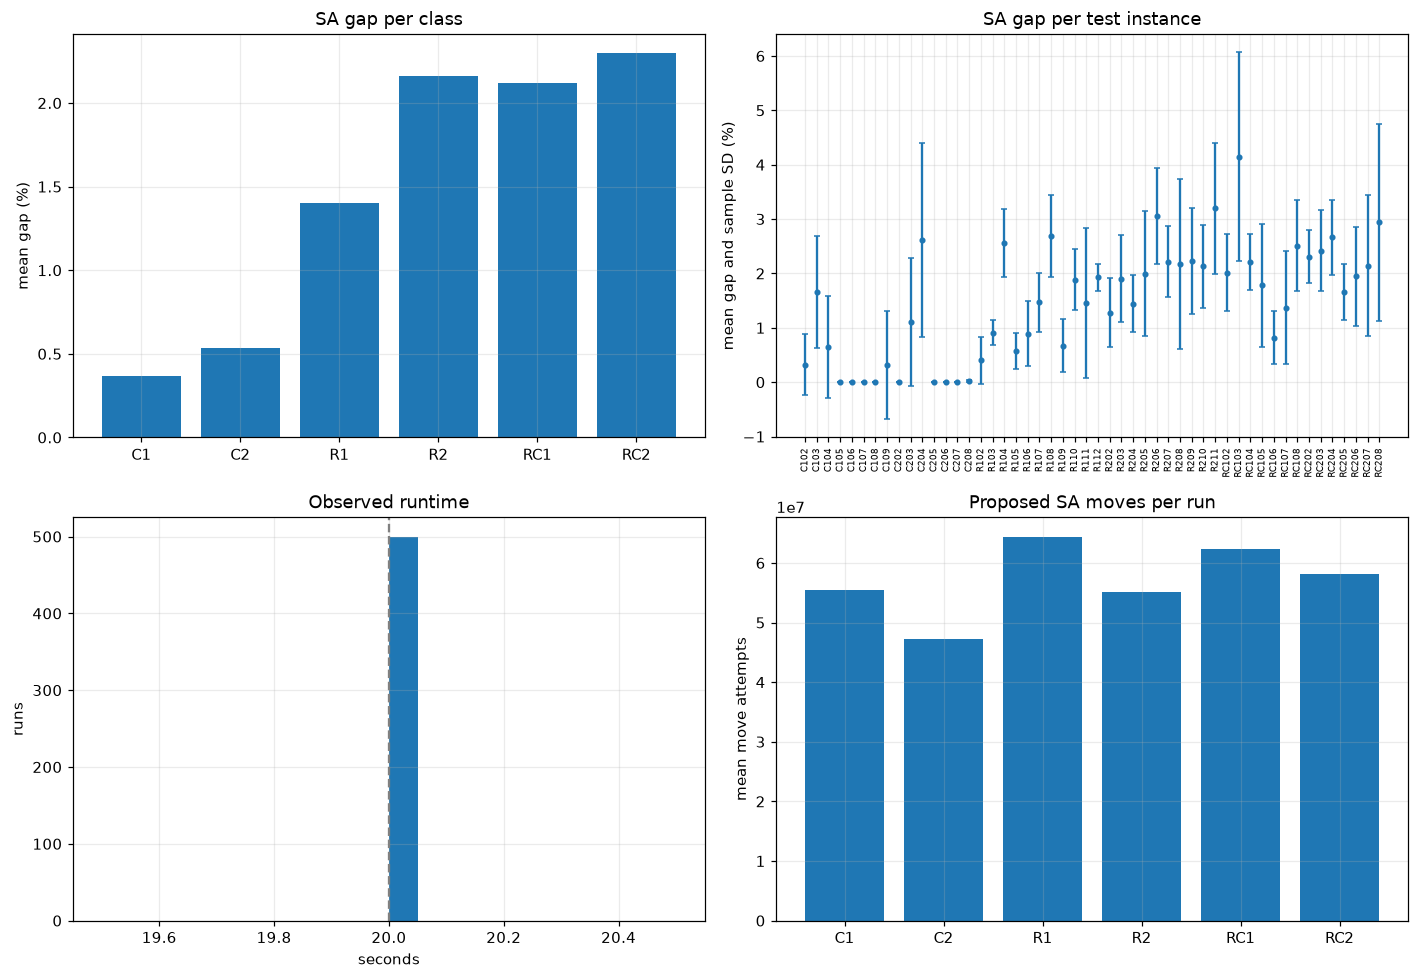

Largest seed variability:


,instance,gap_mean,gap_std
37,RC103,4.147,1.917
49,RC208,2.942,1.816
10,C204,2.610,1.783
32,R208,2.175,1.557
24,R111,1.454,1.382


In [8]:
cls = bench.groupby('class').agg(
    instances=('instance', 'nunique'), mean_gap=('gap', 'mean'), worst_gap=('gap', 'max'),
    mean_seconds=('seconds', 'mean'), mean_iterations=('iterations', 'mean'),
).reindex(CLASSES)
display(cls)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0, 0].bar(CLASSES, cls.mean_gap)
axes[0, 0].set(title='SA gap per class', ylabel='mean gap (%)')
order = per_inst.sort_values('instance').reset_index(drop=True)
axes[0, 1].errorbar(order.index, order.gap_mean, yerr=order.gap_std, fmt='o', ms=3, capsize=2)
axes[0, 1].set(title='SA gap per test instance', ylabel='mean gap and sample SD (%)')
axes[0, 1].set_xticks(order.index, order.instance, rotation=90, fontsize=6)
axes[1, 0].hist(bench.seconds, bins=20)
axes[1, 0].axvline(TIME_LIMIT, ls='--', color='gray')
axes[1, 0].set(title='Observed runtime', xlabel='seconds', ylabel='runs')
axes[1, 1].bar(CLASSES, cls.mean_iterations)
axes[1, 1].set(title='Proposed SA moves per run', ylabel='mean move attempts')
for ax in axes[0]:
    ax.ticklabel_format(axis='y', style='plain', useOffset=False)
plt.tight_layout(); plt.show()
print('Largest seed variability:')
display(per_inst.nlargest(5, 'gap_std')[['instance', 'gap_mean', 'gap_std']])

## 9. Statistical analysis of SA

The statistical unit is the instance, not each of the 500 repeated runs. The table summarizes per-instance mean gaps within each class and a Student-t interval over those means. It describes this fixed benchmark rather than guaranteeing performance on unseen instances.

This section analyzes SA only. It does not load another algorithm's results or perform paired algorithm tests.


In [9]:
def ci95(values):
    values = np.asarray(values, dtype=float)
    return stats.t.ppf(0.975, len(values)-1) * values.std(ddof=1) / np.sqrt(len(values))

inst_means = bench.groupby(['class', 'instance']).gap.mean().reset_index()
table9 = inst_means.groupby('class').gap.agg(instances='size', mean='mean', ci95=ci95).reindex(CLASSES)
display(table9)

,instances,mean,ci95
class,,,
C1,8,0.368,0.478
C2,7,0.533,0.929
R1,11,1.403,0.531
R2,10,2.162,0.431
RC1,7,2.122,0.973
RC2,7,2.297,0.400


## 10. Conclusions and limitations

Conclusions are computed from the executed SA tables. The full experiment is required before using these numbers in the report; quick-check runs are labelled and are not benchmark evidence.

All benchmark instances contain 100 customers. These results do not establish scaling to larger problems or performance with time-dependent traffic. Some test cases were examined during earlier exploratory development; tuning on the six reserved instances makes current parameter selection explicit but does not erase that history.


In [11]:
if QUICK_CHECK:
    print('QUICK CHECK ONLY: do not use these numbers in the benchmark report.')
print(f'Tuning: {len(tuning)} runs, chosen {CHOSEN}')
print(f'Test: {len(bench)} runs across {bench.instance.nunique()} instances; '
      f'mean gap {bench.gap.mean():.3f}%, all feasible {bench.feasible.all()}')
print(f'Median per-instance seed SD: {per_inst.gap_std.median():.3f} percentage points')
print(f'Mean runtime: {bench.seconds.mean():.3f} s; mean proposed moves: {bench.iterations.mean():,.0f}')

Tuning: 144 runs, chosen {'initial_temperature_factor': 0.01, 'final_temperature': 0.005}
Test: 500 runs across 50 instances; mean gap 1.493%, all feasible True
Median per-instance seed SD: 0.640 percentage points
Mean runtime: 20.000 s; mean proposed moves: 57,548,737


## 11. SA on a single 10,000-customer NetworkX graph

This section uses one reproducible uniform geometric graph: 10,000 customers plus depot node 0, capacity 100, graph seed 101 and solver seed 1. NetworkX generates the spatial graph. Its sparse proximity edges describe the layout; routing uses complete Euclidean distances computed from the node positions, rather than shortest paths along proximity edges. The distance matrix alone occupies about 0.80 GB in float64.

There is no quick check or multi-size campaign. Only SA runs on this instance. A feasible sweep solution initializes the shared solver. Synthetic data have no known optimum, so improvement is measured against that initial solution, not an optimality gap. The earlier benchmark cells and saved results remain unchanged.


In [ ]:
import networkx as nx
from scipy.spatial.distance import cdist
from cvrp.instance import Instance

def synthetic_instance(n, layout, capacity, graph_seed):
    """Generate NetworkX positions; avoid Python objects for all O(n^2) edges."""
    rng = np.random.default_rng(graph_seed)
    if layout == 'uniform':
        customers = rng.uniform(0, 100, (n, 2))
    elif layout == 'clustered':
        centers = rng.uniform(10, 90, (8, 2))
        customers = np.clip(centers[rng.integers(0, 8, n)]
                            + rng.normal(0, 4, (n, 2)), 0, 100)
    else:
        raise ValueError(f'Unknown layout: {layout}')
    coords = np.vstack(([50.0, 50.0], customers))
    positions = {i: tuple(xy) for i, xy in enumerate(coords)}
    graph = nx.random_geometric_graph(n + 1, radius=3.0, pos=positions,
                                     seed=graph_seed)
    demands = np.r_[0.0, rng.integers(1, 11, n).astype(float)]
    nx.set_node_attributes(graph, dict(enumerate(demands)), 'demand')
    # cdist allocates one dense matrix, avoiding a large (n,n,2) temporary.
    distance = cdist(np.array([graph.nodes[i]['pos'] for i in range(n + 1)]), coords)
    instance = Instance(name=f'nx-{layout}-n{n}-q{capacity:g}-g{graph_seed}',
                        coords=coords, demands=demands, capacity=capacity, dist=distance)
    return graph, instance


def synthetic_sweep(instance):
    """O(n log n) capacity-feasible common start, independent of reference results."""
    xy = instance.coords[1:] - instance.coords[0]
    order = np.argsort(np.arctan2(xy[:, 1], xy[:, 0])) + 1
    routes, route, load = [], [], 0.0
    for node in order:
        if route and load + instance.demands[node] > instance.capacity:
            routes.append(route)
            route, load = [], 0.0
        route.append(int(node))
        load += instance.demands[node]
    if route:
        routes.append(route)
    return Solution(routes)


### Initial customer and depot layout

All 10,000 customers are shown in blue, with depot node 0 marked by a red star at (50, 50). This is the input layout before constructing or optimizing routes. Proximity edges are omitted for clarity; the SA cost matrix still uses complete Euclidean distances.


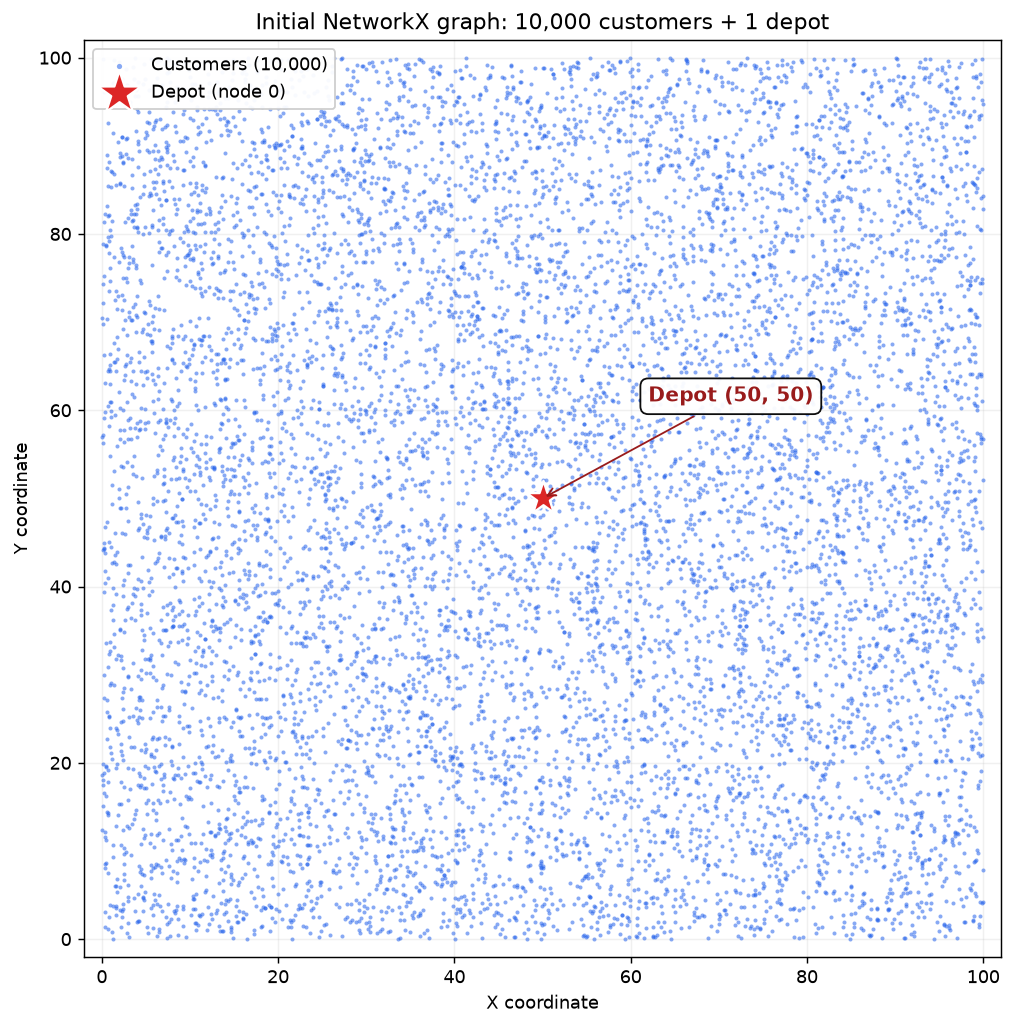

In [ ]:
# Initial spatial graph: all customers and the depot, before route construction.
import matplotlib.pyplot as plt

synthetic_large_graph, synthetic_large_instance = synthetic_instance(10000, 'uniform', 100.0, 101)
synthetic_layout_positions = nx.get_node_attributes(synthetic_large_graph, 'pos')
synthetic_layout_fig, synthetic_layout_ax = plt.subplots(figsize=(9, 8))
synthetic_customer_points = nx.draw_networkx_nodes(
    synthetic_large_graph, synthetic_layout_positions,
    nodelist=list(range(1, synthetic_large_instance.n_customers + 1)),
    node_size=5, node_color='#2563eb', alpha=0.55, linewidths=0,
    label='Customers (10,000)', ax=synthetic_layout_ax)
synthetic_customer_points.set_rasterized(True)
synthetic_depot_xy = synthetic_large_instance.coords[0]
synthetic_layout_ax.scatter(*synthetic_depot_xy, marker='*', s=380, color='#dc2626',
                            edgecolor='white', linewidth=1.3, zorder=5,
                            label='Depot (node 0)')
synthetic_layout_ax.annotate('Depot (50, 50)', xy=synthetic_depot_xy, xytext=(62, 61),
                            fontsize=11, fontweight='bold', color='#991b1b',
                            bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.95),
                            arrowprops=dict(arrowstyle='->', color='#991b1b'), zorder=6)
synthetic_layout_ax.set(title='Initial NetworkX graph: 10,000 customers + 1 depot',
                        xlabel='X coordinate', ylabel='Y coordinate',
                        xlim=(-2, 102), ylim=(-2, 102))
synthetic_layout_ax.set_aspect('equal')
synthetic_layout_ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
synthetic_layout_ax.grid(alpha=0.18)
synthetic_layout_ax.legend(loc='upper left', framealpha=0.95, markerscale=1.3)
synthetic_layout_fig.tight_layout()
plt.show()
del synthetic_large_graph  # Keep the instance for the shared SA run below.


### 11.1 Shared SA solver on 10,000 customers, without a time limit

This section calls the same public `sa()` solver as the earlier sections, using `SAParams(time_limit=None, iterations=10_000_000)`. It reuses the shared move kernel, Metropolis acceptance, feasibility checks and best-solution tracking. The same exponential temperature interpolation now follows proposed move count instead of elapsed time: T = T0 ? (Tf / T0)^progress. With no deadline, progress is the fraction of the 10 million move attempts completed; the last batch reaches Tf = 0.02. Rejected and infeasible proposals count as attempts. The run stops after completing this finite cooling schedule, without claiming optimality.

A feasible sweep solution initializes the run through the public `initial` argument. Graph generation and sweep construction occur before the solver timer. Existing callers with a numeric `time_limit` retain their timed behavior and defaults; saved outputs in sections 1?10 are preserved. Untimed runs also bound route-array padding by positive customer demands and capacity, reducing memory copies while keeping all feasible moves available.


In [ ]:
# Same public SA entry point and parameters as the other notebook sections.
synthetic_large_initial = synthetic_sweep(synthetic_large_instance)
synthetic_large_params = SAParams(time_limit=None, iterations=10_000_000)
synthetic_large_run = sa(synthetic_large_instance, synthetic_large_params, seed=1,
                         initial=synthetic_large_initial)
assert synthetic_large_run.best is not None
assert synthetic_large_run.best.is_feasible(synthetic_large_instance)
synthetic_large_solution = synthetic_large_run.best
synthetic_large_initial_cost = synthetic_large_initial.cost(synthetic_large_instance)
synthetic_large_history = pd.DataFrame(synthetic_large_run.history).rename(columns={'best': 'cost', 'iteration': 'iterations'})
synthetic_large_result = pd.DataFrame([dict(
    customers=10000, layout='uniform', capacity=100.0, graph_seed=101, solver_seed=1,
    time_limit=synthetic_large_params.time_limit,
    scheduled_moves=synthetic_large_params.iterations,
    initial_temperature_factor=synthetic_large_params.initial_temperature_factor,
    final_temperature=synthetic_large_params.final_temperature,
    initial_cost=synthetic_large_initial_cost, cost=synthetic_large_run.cost,
    improvement_pct=100*(synthetic_large_initial_cost-synthetic_large_run.cost)/synthetic_large_initial_cost,
    routes=len(synthetic_large_solution.routes), iterations=synthetic_large_run.iterations,
    accepted=synthetic_large_run.accepted, seconds=synthetic_large_run.runtime,
    feasible=synthetic_large_solution.is_feasible(synthetic_large_instance),
    stop_reason=synthetic_large_run.stop_reason)])
print(synthetic_large_result.to_string(index=False))


 customers  layout  capacity  graph_seed  solver_seed time_limit  scheduled_moves  initial_temperature_factor  final_temperature  initial_cost          cost  improvement_pct  routes  iterations  accepted   seconds  feasible stop_reason
     10000 uniform     100.0         101            1       None         10000000                       0.005               0.02  189072.07597 119173.682498        36.969179     672    10000000   3357319 59.638308      True  iterations


### 11.2 Graphs of the shared, untimed SA run

Convergence uses the shared solver's measured best-improvement history. The temperature plot shows the configured exponential schedule against proposed move count. Improvement over elapsed time, route loads and both maps refer to the same execution above. Elapsed seconds are measured, not a stopping criterion. Both maps include all customers and routes, with repeated colors and transparent lines to limit clutter. These are single-run diagnostics, not averages over multiple seeds.


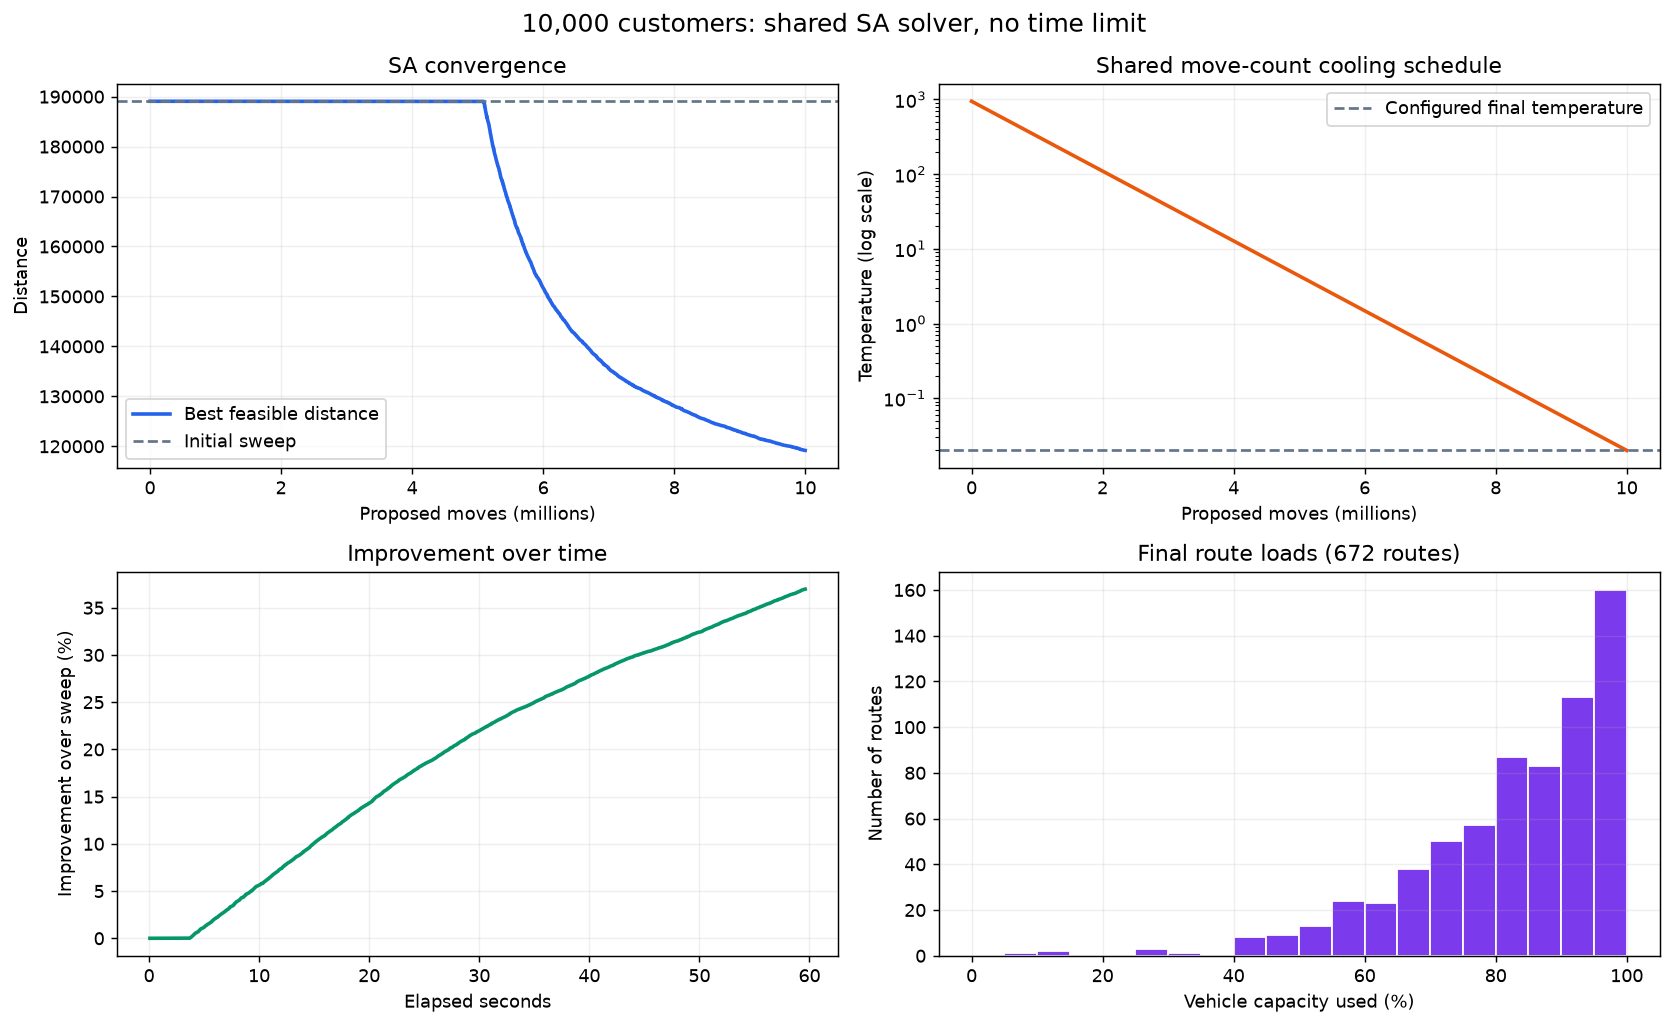

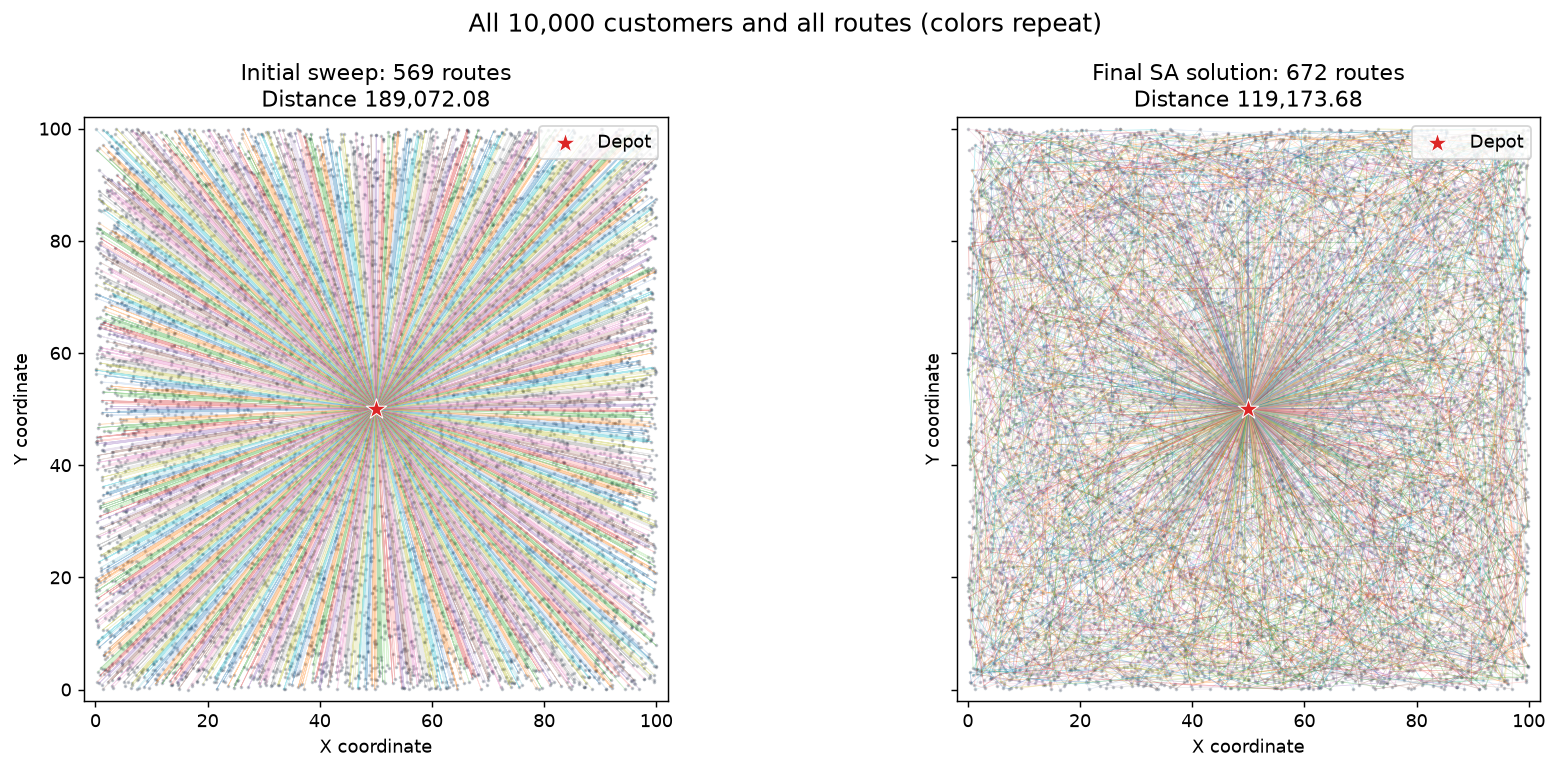

In [ ]:
# Graphs use the shared SA result and measured improvement history above.
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

synthetic_plot_history = synthetic_large_history.copy()
synthetic_schedule_moves = np.linspace(0, synthetic_large_params.iterations, 300)
synthetic_schedule_t0 = max(1.0, synthetic_large_result.initial_cost.iloc[0]
                            * synthetic_large_params.initial_temperature_factor)
synthetic_schedule_temperature = synthetic_schedule_t0 * (
    synthetic_large_params.final_temperature / synthetic_schedule_t0
) ** (synthetic_schedule_moves / synthetic_large_params.iterations)
synthetic_plot_initial_cost = synthetic_large_result.initial_cost.iloc[0]
synthetic_plot_improvement = 100 * (1 - synthetic_plot_history.cost / synthetic_plot_initial_cost)
synthetic_plot_millions = synthetic_plot_history.iterations / 1e6

synthetic_diagnostics, synthetic_diagnostic_axes = plt.subplots(2, 2, figsize=(13, 8))
synthetic_diagnostic_axes[0, 0].plot(synthetic_plot_millions, synthetic_plot_history.cost,
                                   color='#2563eb', linewidth=2, label='Best feasible distance')
synthetic_diagnostic_axes[0, 0].axhline(synthetic_plot_initial_cost, color='#64748b',
                                      linestyle='--', label='Initial sweep')
synthetic_diagnostic_axes[0, 0].set(xlabel='Proposed moves (millions)', ylabel='Distance',
                                  title='SA convergence')
synthetic_diagnostic_axes[0, 0].legend()
synthetic_diagnostic_axes[0, 1].plot(synthetic_schedule_moves / 1e6, synthetic_schedule_temperature,
                                   color='#ea580c', linewidth=2)
synthetic_diagnostic_axes[0, 1].axhline(synthetic_large_params.final_temperature, color='#64748b',
                                      linestyle='--', label='Configured final temperature')
synthetic_diagnostic_axes[0, 1].set(yscale='log', xlabel='Proposed moves (millions)',
                                  ylabel='Temperature (log scale)', title='Shared move-count cooling schedule')
synthetic_diagnostic_axes[0, 1].legend()
synthetic_diagnostic_axes[1, 0].plot(synthetic_plot_history.seconds, synthetic_plot_improvement,
                                   color='#059669', linewidth=2)
synthetic_diagnostic_axes[1, 0].set(xlabel='Elapsed seconds',
                                  ylabel='Improvement over sweep (%)', title='Improvement over time')
synthetic_plot_loads = np.array([
    synthetic_large_instance.demands[route].sum()
    for route in synthetic_large_solution.routes])
synthetic_diagnostic_axes[1, 1].hist(synthetic_plot_loads / synthetic_large_instance.capacity * 100,
                                   bins=np.linspace(0, 100, 21), color='#7c3aed', edgecolor='white')
synthetic_diagnostic_axes[1, 1].set(xlabel='Vehicle capacity used (%)', ylabel='Number of routes',
                                  title=f'Final route loads ({len(synthetic_plot_loads)} routes)')
for synthetic_plot_ax in synthetic_diagnostic_axes.flat:
    synthetic_plot_ax.grid(alpha=0.2)
synthetic_diagnostics.suptitle('10,000 customers: shared SA solver, no time limit', fontsize=14)
synthetic_diagnostics.tight_layout()
plt.show()

# LineCollection draws every route without 10,000 separate point markers or a huge legend.
synthetic_maps, synthetic_map_axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
synthetic_plot_xy = synthetic_large_instance.coords
for synthetic_map_ax, synthetic_map_solution, synthetic_map_title in zip(
        synthetic_map_axes,
        (synthetic_large_initial, synthetic_large_solution),
        ('Initial sweep', 'Final SA solution')):
    synthetic_paths = [synthetic_plot_xy[[0, *route, 0]] for route in synthetic_map_solution.routes]
    synthetic_colors = plt.get_cmap('tab20')(np.arange(len(synthetic_paths)) % 20)
    synthetic_map_ax.add_collection(LineCollection(synthetic_paths, colors=synthetic_colors,
                                                   linewidths=0.4, alpha=0.35))
    synthetic_map_ax.scatter(synthetic_plot_xy[1:, 0], synthetic_plot_xy[1:, 1],
                             s=1, color='#334155', alpha=0.25, rasterized=True)
    synthetic_map_ax.scatter(*synthetic_plot_xy[0], marker='*', s=140, color='#dc2626',
                             edgecolor='white', linewidth=0.6, zorder=5, label='Depot')
    synthetic_map_ax.set(xlim=(-2, 102), ylim=(-2, 102), xlabel='X coordinate', ylabel='Y coordinate',
                         title=f'{synthetic_map_title}: {len(synthetic_map_solution.routes)} routes'
                               f'\nDistance {synthetic_map_solution.cost(synthetic_large_instance):,.2f}')
    synthetic_map_ax.set_aspect('equal')
    synthetic_map_ax.legend(loc='upper right')
synthetic_maps.suptitle('All 10,000 customers and all routes (colors repeat)', fontsize=14)
synthetic_maps.tight_layout()
plt.show()
